# Import Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset

In [4]:
df = pd.read_csv(r"C:\smec\Projects\Pandas project\factory_datset.csv")

# Initial Inspection

In [50]:
#First five columns
df.head()

,record_id,device_id,timestamp,signal_strength_dBm,packet_loss_pct,temperature_C,vibration_mm_s,humidity_pct,pressure_kPa,current_A,voltage_V,power_factor,power_kW,energy_cumulative_kWh,rpm,tool_wear_hrs,operating_hours,load_type,fault_flag,failure_type
0,9721,IoT-M10,2026-09-08 12:00:00,-52.30,0.036,52.810,1.874,32.86,99.67,11.127,228.15,0.920,2.3361,464.3405,1399.7,8.6298,203.18,Medium Load,0,No Fault
1,7870,IoT-M08,2026-09-10 01:15:00,-55.75,2.003,46.670,2.401,34.18,96.07,9.040,231.51,0.919,1.9241,478.4079,1359.6,5.5244,285.66,Light Load,0,No Fault
2,7579,IoT-M08,2026-09-07 00:30:00,-49.71,1.181,47.225,2.421,33.09,96.70,9.498,234.93,0.922,2.0575,325.7913,1413.6,3.7975,212.91,Light Load,0,No Fault
3,7066,IoT-M08,2026-09-01 16:15:00,-52.66,0.610,42.710,2.904,37.24,97.00,8.744,234.75,0.885,1.8156,57.6645,1373.8,0.7185,84.66,Light Load,0,No Fault
4,4212,IoT-M05,2026-09-03 04:45:00,-56.29,0.747,43.100,2.332,45.55,97.63,10.232,225.28,0.891,2.0540,106.8599,1411.5,3.2509,151.93,Light Load,0,No Fault


In [5]:
df.shape

(10050, 20)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10050 entries, 0 to 10049
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   record_id              10050 non-null  int64  
 1   device_id              10050 non-null  object 
 2   timestamp              10050 non-null  object 
 3   signal_strength_dBm    9908 non-null   float64
 4   packet_loss_pct        10050 non-null  float64
 5   temperature_C          9894 non-null   float64
 6   vibration_mm_s         9928 non-null   float64
 7   humidity_pct           9906 non-null   float64
 8   pressure_kPa           9899 non-null   float64
 9   current_A              9893 non-null   float64
 10  voltage_V              9902 non-null   float64
 11  power_factor           10050 non-null  float64
 12  power_kW               10050 non-null  float64
 13  energy_cumulative_kWh  10050 non-null  float64
 14  rpm                    10050 non-null  float64
 15  to

# Missing-Value Analysis

In [ ]:
#Missing Values from 7 columns
df.isnull().sum()

record_id                  0
device_id                  0
timestamp                  0
signal_strength_dBm      142
packet_loss_pct            0
temperature_C            156
vibration_mm_s           122
humidity_pct             144
pressure_kPa             151
current_A                157
voltage_V                148
power_factor               0
power_kW                   0
energy_cumulative_kWh      0
rpm                        0
tool_wear_hrs              0
operating_hours            0
load_type                  0
fault_flag                 0
failure_type               0
dtype: int64

In [ ]:
#Missing values from the column. Found values and percentage missing from 7 sensor column
missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage' : df.isnull().mean()*100
})
missing[missing['Missing Values']>0].sort_values(
    'Missing Percentage',ascending=False
)

,Missing Values,Missing Percentage
temperature_C,155,1.55
current_A,155,1.55
pressure_kPa,151,1.51
voltage_V,147,1.47
humidity_pct,144,1.44
signal_strength_dBm,142,1.42
vibration_mm_s,122,1.22


# Duplicate Analysis

In [ ]:
#Duplicated Values
df.duplicated().sum()

50

In [ ]:
#To find if every record id is unique. Not all is unique
df['record_id'].is_unique

False

In [ ]:
#Duplicated values from the record id column
df[df.duplicated(keep=False)].sort_values('record_id')

,record_id,device_id,timestamp,signal_strength_dBm,packet_loss_pct,temperature_C,vibration_mm_s,humidity_pct,pressure_kPa,current_A,voltage_V,power_factor,power_kW,energy_cumulative_kWh,rpm,tool_wear_hrs,operating_hours,load_type,fault_flag,failure_type
792,170,IoT-M01,2026-09-02 18:15:00,-56.48,1.729,49.60,1.835,51.50,104.82,14.856,222.62,0.936,3.0959,171.8912,1405.6,4.3330,83.14,Maximum Load,0,No Fault
1996,170,IoT-M01,2026-09-02 18:15:00,-56.48,1.729,49.60,1.835,51.50,104.82,14.856,222.62,0.936,3.0959,171.8912,1405.6,4.3330,83.14,Maximum Load,0,No Fault
2144,526,IoT-M01,2026-09-06 11:15:00,-35.33,0.234,53.74,2.875,58.18,104.19,14.768,219.81,0.938,3.0440,446.8063,1394.0,6.3885,172.14,Maximum Load,0,No Fault
6580,526,IoT-M01,2026-09-06 11:15:00,-35.33,0.234,53.74,2.875,58.18,104.19,14.768,219.81,0.938,3.0440,446.8063,1394.0,6.3885,172.14,Maximum Load,0,No Fault
4945,1055,IoT-M02,2026-09-01 13:30:00,-70.15,2.027,36.63,2.636,41.51,108.78,13.929,231.52,0.897,2.8912,51.2111,1426.2,4.6689,91.75,Maximum Load,0,No Fault
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7353,9596,IoT-M10,2026-09-07 04:45:00,-48.57,1.550,54.32,2.231,32.74,99.36,NaN,228.26,0.909,2.4409,389.3624,1392.8,7.8916,171.93,Medium Load,0,No Fault
6190,9655,IoT-M10,2026-09-07 19:30:00,-41.32,1.510,55.31,1.963,29.50,98.17,12.150,223.65,0.922,2.5066,424.8139,1396.7,8.2395,186.68,Medium Load,0,No Fault
9028,9655,IoT-M10,2026-09-07 19:30:00,-41.32,1.510,55.31,1.963,29.50,98.17,12.150,223.65,0.922,2.5066,424.8139,1396.7,8.2395,186.68,Medium Load,0,No Fault
2932,9828,IoT-M10,2026-09-09 14:45:00,-40.87,0.317,51.29,2.281,31.49,98.25,12.202,228.45,0.917,2.5552,528.2742,1434.4,9.2391,229.93,Medium Load,0,No Fault


In [ ]:
#Duplicated values that appear more than once
df['record_id'].value_counts().loc[lambda x:x>1]

4144    2
3188    2
3371    2
6391    2
9554    2
4340    2
9596    2
8736    2
3595    2
9181    2
3123    2
9262    2
1125    2
2593    2
9828    2
5122    2
8226    2
3208    2
2087    2
6464    2
4276    2
9655    2
7976    2
5653    2
3109    2
7853    2
9234    2
2830    2
8539    2
8999    2
4542    2
1055    2
7869    2
1722    2
1729    2
526     2
6132    2
5539    2
4709    2
6569    2
6890    2
3030    2
3342    2
4001    2
9326    2
9445    2
170     2
1592    2
4886    2
3918    2
Name: record_id, dtype: int64

# Data Cleaning

In [15]:
#There were 50 duplicated values and it has been removed
df= df.drop_duplicates()
df.shape

(10000, 20)

In [16]:
#Cleaning the sensor column. These seven sensor column had missing value and it is filled with the median value of each column.
sensor_cols = [
    'temperature_C','current_A','pressure_kPa','voltage_V','humidity_pct','signal_strength_dBm','vibration_mm_s'
]
for col in sensor_cols:
    df[col] = df[col].fillna(df[col].median())
df[sensor_cols].isnull().sum()

temperature_C          0
current_A              0
pressure_kPa           0
voltage_V              0
humidity_pct           0
signal_strength_dBm    0
vibration_mm_s         0
dtype: int64

In [17]:
#All the missing values from the data is filled 
df.isnull().sum()

record_id                0
device_id                0
timestamp                0
signal_strength_dBm      0
packet_loss_pct          0
temperature_C            0
vibration_mm_s           0
humidity_pct             0
pressure_kPa             0
current_A                0
voltage_V                0
power_factor             0
power_kW                 0
energy_cumulative_kWh    0
rpm                      0
tool_wear_hrs            0
operating_hours          0
load_type                0
fault_flag               0
failure_type             0
dtype: int64

In [18]:
#Changing the data type of timestamps to date and time
df['timestamp']=pd.to_datetime(df['timestamp'])
df['timestamp'].dtype

dtype('<M8[ns]')

In [ ]:
#Duplicated data is removed
df = df.drop_duplicates().copy()

In [10]:
#Duplicate values are removed
print("Dataset shape:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())

Dataset shape: (10000, 20)
Duplicate rows remaining: 0


In [11]:
#Everything is in order. All adds upto 10,000.
print(df['fault_flag'].value_counts())
print()
print(df['failure_type'].value_counts())

0    9672
1     328
Name: fault_flag, dtype: int64

No Fault             9672
Vibration              92
Overcurrent            87
Power Fluctuation      75
Overheat               74
Name: failure_type, dtype: int64


In [12]:
df['load_type'].value_counts()

Maximum Load    3400
Medium Load     3300
Light Load      3300
Name: load_type, dtype: int64

In [19]:
pd.crosstab(df['fault_flag'], df['failure_type'])

failure_type,No Fault,Overcurrent,Overheat,Power Fluctuation,Vibration
fault_flag,,,,,
0,9672,0,0,0,0
1,0,87,74,75,92


# Exploratory Data Analysis

### 1. Fault rate by load type.
Does the load category relate to fault frequency?

In [20]:
fault_analysis = df.groupby('load_type').agg(
    Total_Record = ('fault_flag','count'),
    Total_Fault = ('fault_flag','sum')
)
fault_analysis['fault_rate_%']=(
    fault_analysis['Total_Fault']/
    fault_analysis['Total_Record'] * 100
)
fault_analysis

,Total_Record,Total_Fault,fault_rate_%
load_type,,,
Light Load,3300,104,3.151515
Maximum Load,3400,138,4.058824
Medium Load,3300,86,2.606061


<function matplotlib.pyplot.show(close=None, block=None)>

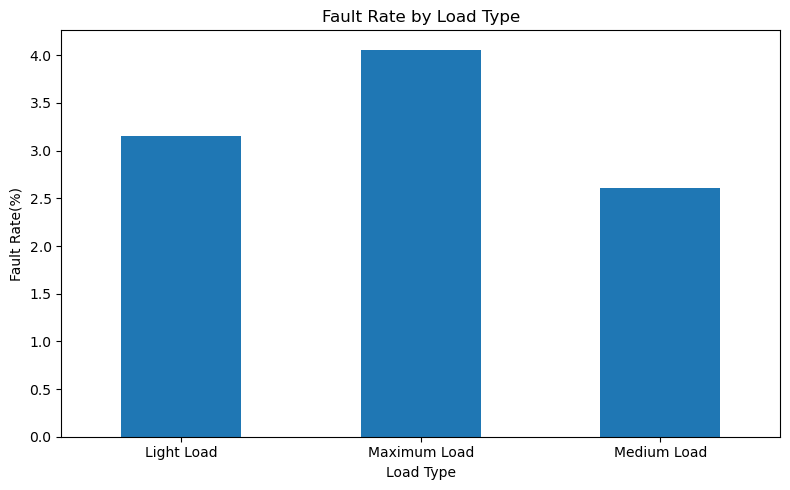

In [22]:
fault_analysis['fault_rate_%'].plot(
    kind='bar',
    figsize=(8,5),
    title='Fault Rate by Load Type',
    xlabel='Load Type',
    ylabel='Fault Rate(%)',
    rot=0
)
plt.tight_layout()
plt.show

##### Interpretation:
Maximum Load recorded the highest fault rate at approximately 4.06%, followed by Light Load at 3.15% and Medium Load at 2.61%. This indicates an association between load category and observed fault frequency in the dataset. Further analysis is needed to determine whether load conditions are related to specific failure types or sensor readings.

### 2. Failure type distribution
Which type of fault occur most frequently in the factory?

In [23]:
failure_counts = df['failure_type'].value_counts()
failure_counts

No Fault             9672
Vibration              92
Overcurrent            87
Power Fluctuation      75
Overheat               74
Name: failure_type, dtype: int64

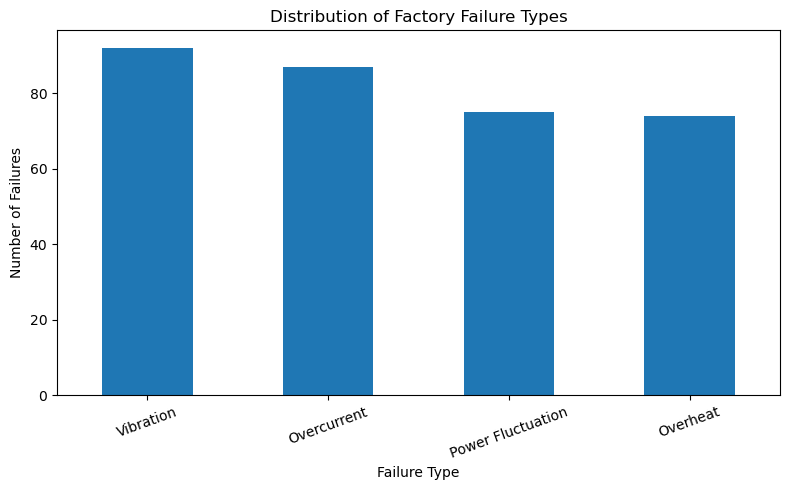

In [24]:
failure_counts.drop('No Fault').plot(
    kind='bar',
    figsize=(8,5),
    title='Distribution of Factory Failure Types',
    xlabel='Failure Type',
    ylabel='Number of Failures',
    rot=20
)
plt.tight_layout()
plt.show()

##### Interpretation:
Vibration was the most frequently recorded failure type, with 92 cases, followed by overcurrent with 87 cases. Power fluctuation and overheating accounted for 75 and 74 cases, respectively.

Vibration represented approximately 28.05% of all recorded failures. This suggests that vibration-related faults deserve further investigation. However, the frequency counts alone do not establish the underlying causes of these failures.

### 3. Fault rate by device
Which devices have the highest percentage of recorded faults?

In [26]:
device_analysis = df.groupby('device_id').agg(
    Total_Records=('fault_flag','count'),
    Total_Faults=('fault_flag','sum')
)
device_analysis['Fault_Rate_%']=(
    device_analysis['Total_Faults']/
    device_analysis['Total_Records'] * 100
)
device_analysis.sort_values(
    'Fault_Rate_%',ascending=False
)

,Total_Records,Total_Faults,Fault_Rate_%
device_id,,,
IoT-M08,1000,44,4.4
IoT-M10,1000,39,3.9
IoT-M06,1000,37,3.7
IoT-M07,1000,37,3.7
IoT-M09,1000,35,3.5
IoT-M02,1000,29,2.9
IoT-M03,1000,29,2.9
IoT-M05,1000,27,2.7
IoT-M04,1000,26,2.6


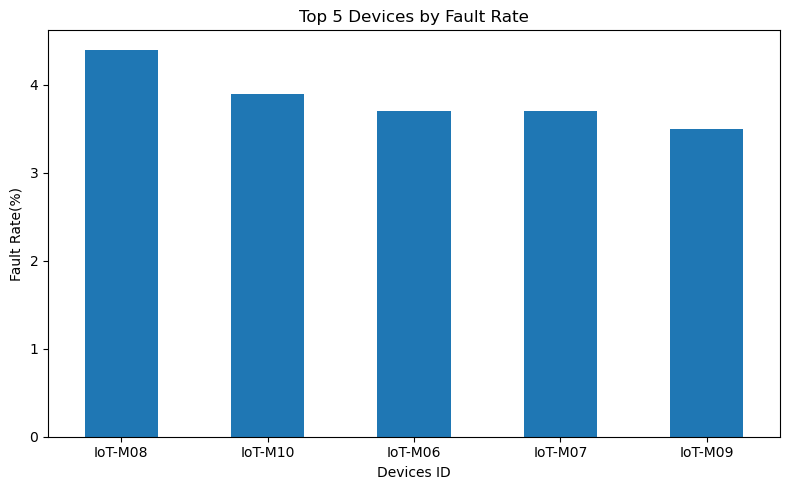

In [27]:
top_devices = device_analysis.sort_values(
    'Fault_Rate_%',ascending=False
).head(5)
top_devices['Fault_Rate_%'].plot(
    kind='bar',
    figsize=(8,5),
    title='Top 5 Devices by Fault Rate',
    xlabel='Devices ID',
    ylabel='Fault Rate(%)',
    rot=0
)
plt.tight_layout()
plt.show()

##### Interpretation
IoT-M08 recorded the highest fault rate at 4.4%, with 44 faults out of 1,000 records. IoT-M10 followed at 3.9%, while IoT-M06 and IoT-M07 each recorded a 3.7% fault rate. IoT-M01 had the lowest rate at 2.5%.

These results identify IoT-M08 as a device that may warrant further investigation. However, the observed differences do not establish the cause of the faults.

### 4.Temperature Analysis
Do temperature readings differ between normal and faulty records?

In [ ]:
temperature_analysis